# Cây quyết định ID3 xây dựng từ dữ liệu thời tiết (mục 6.1.2)

Mỗi nút ghi phép kiểm tra (hoặc nhãn), số mẫu Yes/No và entropy

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

(x, y, nội dung, loại nút): loại 'test' là nút gốc/trung gian, 'Yes'/'No' là nút lá

In [2]:
nodes = {
    'root':   (0.50, 0.88, 'weather?\n10 mẫu: 5 Yes / 5 No\nH = 1.000', 'test'),
    'sunny':  (0.17, 0.52, 'humidity?\n3 mẫu: 1 Yes / 2 No\nH = 0.918', 'test'),
    'cloudy': (0.50, 0.52, 'Yes\n3 mẫu: 3 Yes / 0 No\nH = 0', 'Yes'),
    'rainy':  (0.83, 0.52, 'wind?\n4 mẫu: 1 Yes / 3 No\nH = 0.811', 'test'),
    's_high': (0.06, 0.13, 'No\n2 mẫu: 0 / 2', 'No'),
    's_norm': (0.28, 0.13, 'Yes\n1 mẫu: 1 / 0', 'Yes'),
    'r_weak': (0.72, 0.13, 'Yes\n1 mẫu: 1 / 0', 'Yes'),
    'r_strg': (0.94, 0.13, 'No\n3 mẫu: 0 / 3', 'No'),
}
# (nút cha, nút con, nhãn nhánh)
edges = [('root', 'sunny', 'Sunny'), ('root', 'cloudy', 'Cloudy'), ('root', 'rainy', 'Rainy'),
         ('sunny', 's_high', 'High'), ('sunny', 's_norm', 'Normal'),
         ('rainy', 'r_weak', 'Weak'), ('rainy', 'r_strg', 'Strong')]
colors = {'test': '#E8EEF7', 'Yes': '#D4EDDA', 'No': '#F8D7DA'}

Vẽ hình và lưu ảnh.

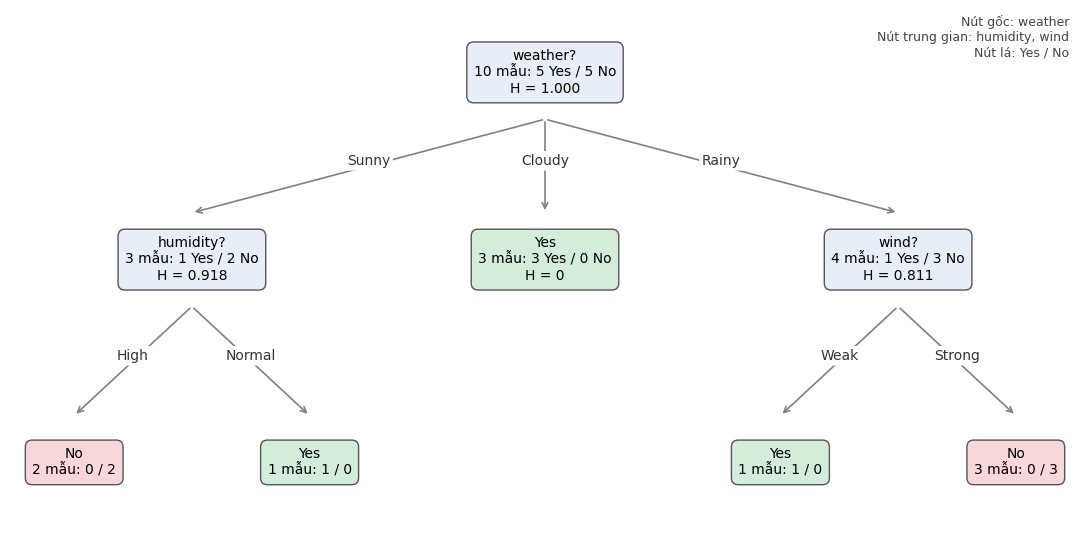

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
for parent, child, label in edges:
    x0, y0 = nodes[parent][:2]
    x1, y1 = nodes[child][:2]
    ax.annotate('', xy=(x1, y1 + 0.09), xytext=(x0, y0 - 0.09),
                arrowprops=dict(arrowstyle='->', color='gray', lw=1.2))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.01, label, ha='center', va='center', fontsize=10,
            color='#333', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none'))
for name, (x, y, text, kind) in nodes.items():
    ax.text(x, y, text, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.5', fc=colors[kind], ec='#555'))
ax.text(0.99, 0.99, 'Nút gốc: weather\nNút trung gian: humidity, wind\nNút lá: Yes / No',
        ha='right', va='top', fontsize=9, color='#444')
fig.tight_layout()
fig.savefig(IMAGES / 'weather_tree.png', dpi=150)